# CRC internal val — pretrained pan-cancer Hist2Pheno

Xenium CRC, fold 0 is `P2CRC` (P1CRC is fold 1, P5CRC is fold 2).

Checkpoint: `data/PanCancer/result_all_spatial/cross_dataset_cv/D_emph_L2_spatial_pancancer/best_mlp_gpu.pt`  
This is **not** the single-dataset model. Fold 0 was held out of that weight file.

```bash
bash code/Internal_val/demo.sh status
ONLY=CRC bash code/Internal_val/demo.sh predict
```


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code" / "Internal_val"))

import internal_val as iv

DATASET = "CRC"
SAVE_FIGURES = False
fold = iv.fold0_table(DATASET)
viz = iv.viz_samples(DATASET)
cov = iv.coverage(DATASET)
print(f"{DATASET} fold 0: {len(fold)} sections; drawing {len(viz)}")
display(cov)
met = iv.metrics_fold0(DATASET)
if not met.empty:
    cols = [c for c in ("sample", "n_matched", "macro_auc_L1_cells", "macro_auc_L12_cells", "macro_auc_L2_cells") if c in met]
    display(met[cols])
print("viz", viz)


CRC fold 0: 1 sections; drawing 1


,dataset,sample,n_keep,pred,panel,star
0,CRC,P2CRC,202900,True,True,True


viz ['P2CRC']


## Existing 4×3 panels (GT / Hist2Pheno / ROC / StarDist-all)

### P2CRC

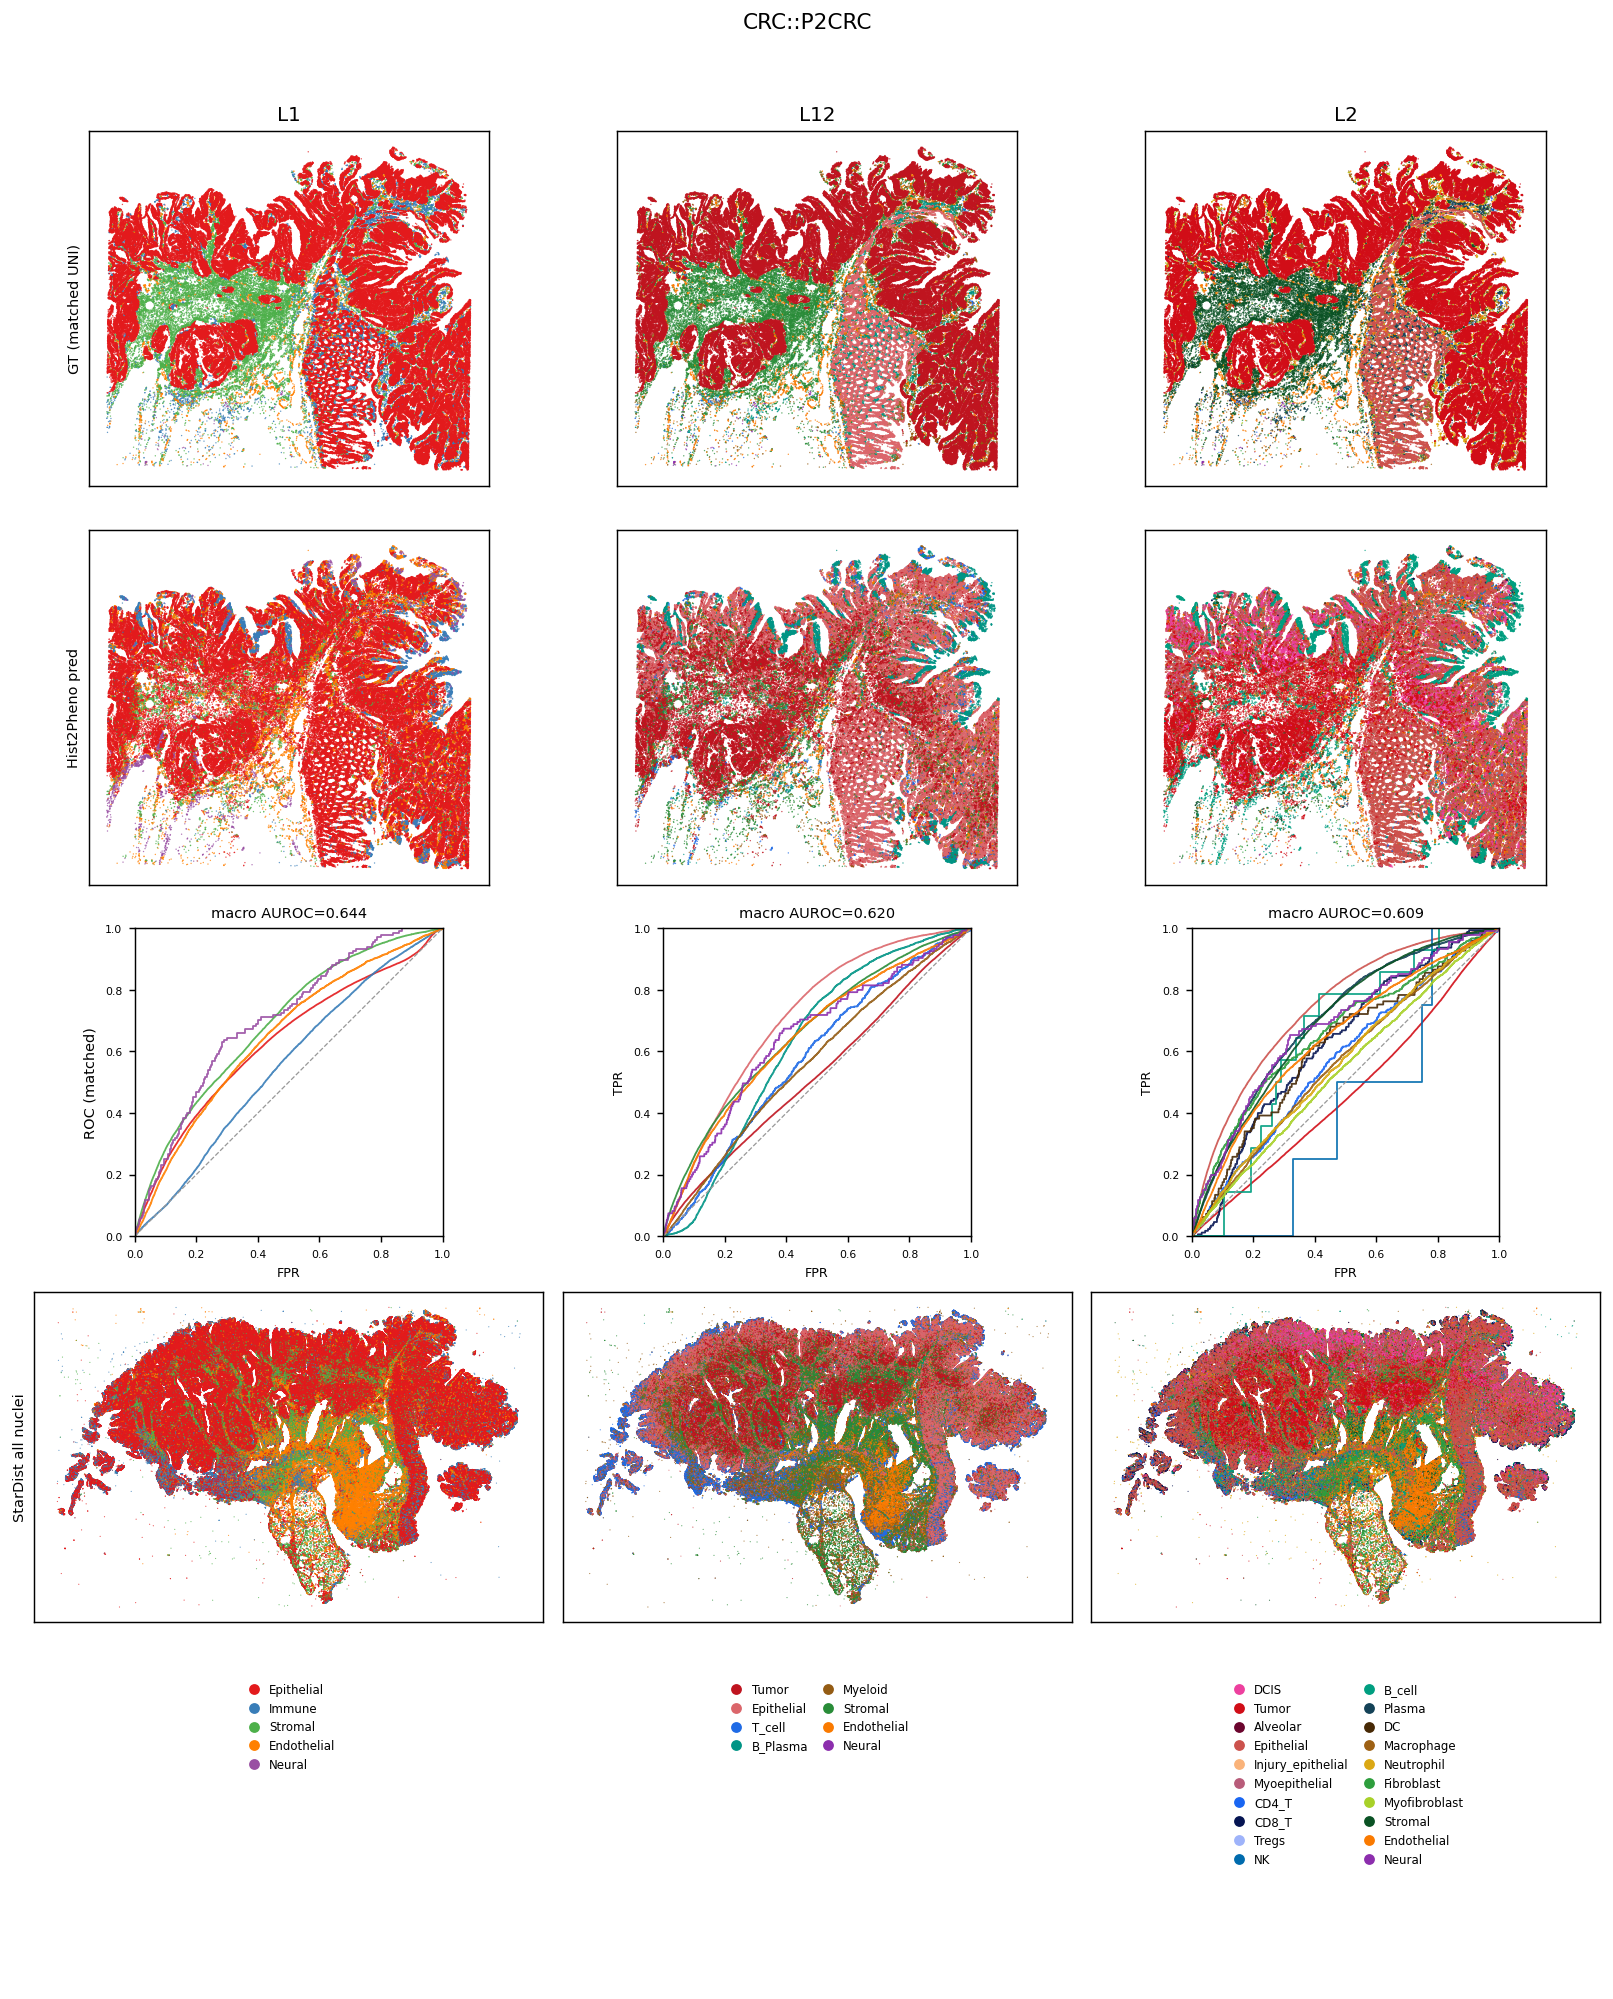

In [2]:
display(Markdown("## Existing 4×3 panels (GT / Hist2Pheno / ROC / StarDist-all)"))
missing = []
for sample in viz:
    panel = iv.pred_paths(DATASET, sample)["panel"]
    if panel.is_file():
        display(Markdown(f"### {sample}"))
        display(Image(filename=str(panel)))
    else:
        missing.append(sample)
        print("missing panel", sample)
if missing:
    print("Run: ONLY=%s bash code/Internal_val/demo.sh predict" % DATASET)


## GT vs pretrained L2 (matched nuclei)

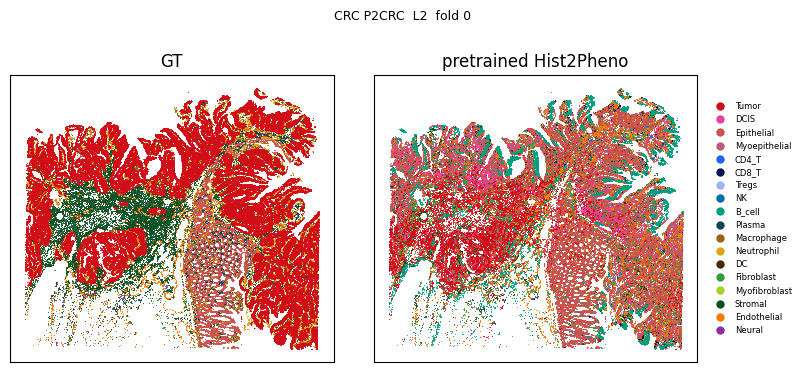

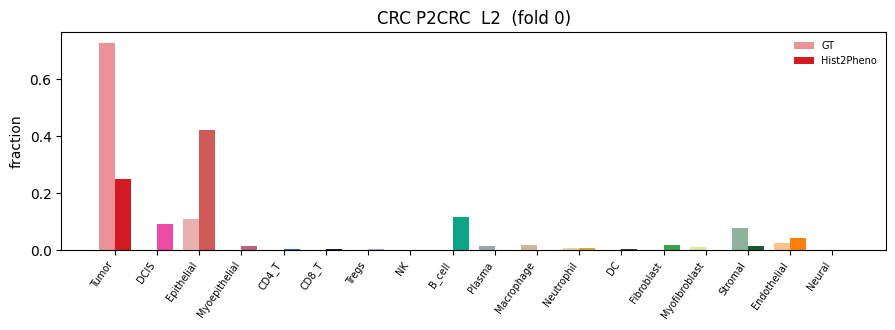

In [3]:
display(Markdown("## GT vs pretrained L2 (matched nuclei)"))
for sample in viz:
    pred = iv.pred_paths(DATASET, sample)["pred"]
    if not pred.is_file():
        print("skip", sample, "(no matched_pred.h5ad)")
        continue
    fig = iv.plot_spatial_gt_pred(DATASET, sample, "L2", save=SAVE_FIGURES)
    display(fig)
    plt.close(fig)
    fig = iv.plot_composition(DATASET, sample, "L2", save=SAVE_FIGURES)
    display(fig)
    plt.close(fig)
